# Neural Network Basics — Coding Tutorial

CSCI3230 / ESTR3108 · Siyuan Huang · Term 1, 2026

This notebook accompanies the tutorial and can also be used for self-study.
Read each explanation, predict the result, then run the next code cell.
To run a code cell, press **Shift + Enter** or click the **▶ run button** beside it.
All examples run on CPU, and all four XOR samples are included here.
You can use this file on its own; no other course files or dataset downloads are needed.

**Recommended: run this notebook in [Google Colab](https://colab.research.google.com/).**
Colab runs notebooks in your browser, so you do not need to install Python or
Jupyter on your own computer. See the [official Colab FAQ](https://research.google.com/colaboratory/faq.html).

1. Download the `.ipynb` file from Blackboard.
2. Open Google Colab, sign in, and choose **File → Upload notebook** to open the file.
3. Use a standard Python runtime with CPU. This small example does not need a GPU.
4. Run **Setup** first, then follow the sections below. Press **Shift + Enter** or
   click the **▶ run button** beside a code cell to run it.

| Section | What you will learn | Slide footer number |
| --- | --- | --- |
| 0 (optional self-study) | Review one neuron's inputs, parameters, logit, and probability | 4–7 |
| 1 | Check a hand calculation with automatic differentiation | 9–11 |
| 2–3 | Build the XOR network and check its dimensions | 14–15 |
| 4–5 | Choose a loss and update the model's parameters | 12, 16–17 |
| 6–7 | Read predictions and inspect the trained boundary | 18–19 |
| 8 | Compare ReLU with Identity and explain the result | 20–21 |

**Local Jupyter is optional:** if you prefer to run the notebook on your own
computer, install PyTorch, NumPy, Matplotlib, and Jupyter in your Python environment.
If you lose track of which cells have run, restart the kernel and run all cells in order.

**Class demonstration:** run Setup, then Sections 1–8 in order. Section 0 is
optional and is not used later in class. Sections 1–8 do not depend on its variables.

**Self-study:** run Setup first. You can work through Section 0 before Section 1,
or return to it later. Plotting code is supplied so you can focus on the neural network.

## Setup

Import PyTorch and its neural-network layers. `torch` provides tensors
and automatic differentiation; `nn` provides layers, activations, and losses.
We use one CPU thread for this small example. This cell does not train a model.

In [1]:
import torch
from torch import nn

torch.set_num_threads(1)

## 0. One output neuron (optional self-study) — slides 4–7

**Optional self-study.**
This section reviews the single-neuron calculation on slides 4–7. Run Setup first.
You can skip this section during class; Sections 1–8 do not use any of its variables.

For one sample, the neuron first computes

$$z=w_1x_1+w_2x_2+b,$$

then converts the score to $p=\sigma(z)$.

- **Inputs** $x_1,x_2$ describe the sample. They are not the parameters we train.
- **Parameters** $w_1,w_2,b$ control the calculation. Each weight scales one
  input feature; the bias adds an offset. Training changes these parameters.
- **Logit** $z$ is the score before sigmoid. It can be negative or positive.
- **Probability estimate** $p$ represents the model's estimate of $P(y=1\mid x)$.
  The estimate for class 0 is $1-p$. It is not a class label.

For this small calculation, choose $x=(1,0)$, $w=(2,-1)$, and $b=-1$ by hand.
Then $z=2(1)-1(0)-1=1$, so $p\approx0.731$.
These chosen parameters have **not** been trained to solve XOR.
Run the cell and match each line to the formula.

In [2]:
neuron_x = torch.tensor([1.0, 0.0])
neuron_w = torch.tensor([2.0, -1.0])
neuron_b = torch.tensor(-1.0)
neuron_z = (neuron_w * neuron_x).sum() + neuron_b
neuron_p = torch.sigmoid(neuron_z)
print(f"Logit z: {neuron_z.item():.1f}")
print(f"Estimated probability of class 1: {neuron_p.item():.3f}")

Logit z: 1.0
Estimated probability of class 1: 0.731


In our larger **2 → 4 → 1** network, four hidden neurons each produce a value
after ReLU. Collect these four values into $h$. The output layer uses them
to calculate one logit $z$, and sigmoid gives the probability $p$.

ReLU changes a negative value to zero and leaves a positive value unchanged.
Hidden values are intermediate features; they are not class probabilities.
The four neurons have different weights and biases. Their parameters are learned together.

## 1. Check the lecture's chain-rule example — slide 11

The lecture's example is $f=(a+b)c$, with $a=-2$, $b=5$, and $c=-4$.
First compute $q=a+b=3$, then $f=qc=-12$.

Since $f=qc$ and $q=a+b$, the partial derivatives at these inputs are

$$\frac{\partial f}{\partial q}=c=-4,\qquad
\frac{\partial q}{\partial a}=\frac{\partial q}{\partial b}=1.$$

Apply the chain rule along $a\to q\to f$:

$$\frac{\partial f}{\partial a}
=\frac{\partial f}{\partial q}\frac{\partial q}{\partial a}
=(-4)(1)=-4.$$

The same calculation gives $\partial f/\partial b=-4$.
Differentiating $f=qc$ with respect to $c$ gives $\partial f/\partial c=q=3$.

Predict the printed values, then run the cell. Expect `-12.0` and `-4.0 -4.0 3.0`.

- `requires_grad=True` asks PyTorch to track operations involving that tensor.
- `f.backward()` applies the chain rule from the scalar output back to the inputs.
- `a.grad`, `b.grad`, and `c.grad` hold the resulting derivatives.
- `.item()` extracts the number from a one-element tensor for printing.

Here $f$ is a simple example, not a neural-network loss. During training we will
use the same rule to differentiate a loss with respect to weights and biases.

In [3]:
a = torch.tensor(-2.0, requires_grad=True)
b = torch.tensor(5.0, requires_grad=True)
c = torch.tensor(-4.0, requires_grad=True)
f = (a + b) * c
f.backward()
print(f.item())
print(a.grad.item(), b.grad.item(), c.grad.item())

-12.0
-4.0 -4.0 3.0


## 2. Data and model — slide 14

XOR assigns label 1 when the two input bits differ, and label 0 when they match.
The four samples are $(0,0),(0,1),(1,0),(1,1)$, with labels $0,1,1,0$.
They cannot all be separated by one straight decision boundary.

`X` stores one sample per row and two features per sample. `y` stores one label
per row, in the **same order**. Floating-point labels are used for the binary loss.
All four points form our training batch.

In [4]:
X = torch.tensor([
    [0., 0.], [0., 1.],
    [1., 0.], [1., 1.]
])
y = torch.tensor([
    [0.], [1.], [1.], [0.]
])

Now build the model. `nn.Sequential` runs its layers in the order listed.

| Code | Calculation for each sample |
| --- | --- |
| `nn.Linear(2, 4)` | Make 4 weighted sums from 2 input features, each with its own bias |
| `nn.ReLU()` | Apply ReLU separately to each of the 4 values |
| `nn.Linear(4, 1)` | Combine the 4 hidden values into 1 logit, including a bias |

`torch.manual_seed(42)` fixes the random initialization for this demonstration.
The layers initialize their own weights and biases; training will change them.
The model returns **logits**, because our training loss expects logits.
We will apply sigmoid when displaying probabilities.

In [5]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(2, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

## 3. Check shapes and count parameters — slide 15

The first dimension below counts **samples**. The second counts values **per sample**.
The number of training samples and the number of hidden neurons happen to both be 4;
they play different roles.

| Tensor | Shape | Meaning |
| --- | --- | --- |
| `X` | `(4, 2)` | 4 samples, 2 input features each |
| `y` | `(4, 1)` | 4 samples, 1 label each |
| `model(X)` | `(4, 1)` | 4 samples, 1 logit each |
| Hidden activations | `(4, 4)` | 4 samples, 4 hidden outputs each |

The first code cell prints the shapes of `X`, `y`, and `model(X)` in that order,
followed by the two weight shapes and the parameter count. The hidden shape is
printed by the next code cell, under **Inspect a forward pass**.

Output and label shapes must match for our loss. Every row uses the **same**
layer parameters; we do not learn a separate network for each sample.

The modules in `nn.Sequential` are indexed from zero:

| Expression | Module | Role | Weight shape |
| --- | --- | --- | --- |
| `model[0]` | `nn.Linear(2, 4)` | First Linear layer (hidden) | `(4, 2)` |
| `model[1]` | `nn.ReLU()` | Hidden activation | No weights |
| `model[2]` | `nn.Linear(4, 1)` | Output Linear layer | `(1, 4)` |

PyTorch stores weights as `(output features, input features)`.
The first Linear layer has four neurons with two inputs each, so its weight matrix
has shape `(4, 2)`. The output Linear layer has one neuron with four inputs, so its
weight matrix has shape `(1, 4)`. The second print statement selects the weight
matrices of `model[0]` and `model[2]`; `model[1]` is ReLU and has no weights to print.

There are $4\times2+4=12$ hidden-layer parameters and $1\times4+1=5$ output-layer
parameters, including the biases. The total is **17**.

Predict the output before running. Expect tensor shapes `(4,2)`, `(4,1)`, `(4,1)`;
weight shapes `(4,2)`, `(1,4)`; and parameter count `17`.
`numel()` counts tensor elements.
In the parameter-count expression, `p` is a parameter tensor, not a predicted probability;
the sum counts all elements of both layers' weight and bias tensors.

In [6]:
print(X.shape, y.shape, model(X).shape)
print(model[0].weight.shape, model[2].weight.shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([4, 2]) torch.Size([4, 1]) torch.Size([4, 1])
torch.Size([4, 2]) torch.Size([1, 4])
17


**Inspect a forward pass.** The next cell opens up `model(X)` into its three steps.
Look at the first sample: two inputs become four hidden values, then one logit.
These are values **before training**. `no_grad()` lets us inspect them without recording gradients.

The final output line prints the hidden tensor's shape, `(4, 4)`.
The first 4 counts samples, and the second 4 counts hidden values per sample.

In [7]:
with torch.no_grad():
    weighted_sums = model[0](X)
    hidden_values = model[1](weighted_sums)
    initial_logits = model[2](hidden_values)
print("First sample:", X[0])
print("Four hidden values:", hidden_values[0])
print("One output logit:", initial_logits[0])
print("Hidden shape:", hidden_values.shape)

First sample: tensor([0., 0.])
Four hidden values: tensor([0.6233, 0.0000, 0.6146, 0.1323])
One output logit: tensor([0.7545])
Hidden shape: torch.Size([4, 4])


## 4. Loss and optimizer — slides 12 and 16

A loss measures how poorly the model's predictions match the labels.
For one sample, let $p=\sigma(z)$:

$$\ell=-[y\log p+(1-y)\log(1-p)].$$

- If $y=1$, the loss is $-\log p$: we want $p$ to increase.
- If $y=0$, the loss is $-\log(1-p)$: we want $p$ to decrease.

For example, $y=1$ with $p=0.9$ gives loss about $0.105$; with $p=0.1$ it gives
loss about $2.303$. A confident wrong prediction has a larger loss.

`BCEWithLogitsLoss` combines sigmoid and binary cross-entropy in a numerically stable
calculation. Give it the **raw logits** from `model(X)` and the labels `y`.
Do not apply sigmoid first. Its default output is the mean loss over our four samples.

SGD uses the gradients to update every tensor in `model.parameters()`.
Here `lr=0.1` sets the learning rate. For each parameter $\theta$, the update is
$\theta \leftarrow \theta-0.1\,\partial L/\partial\theta$.
Creating the optimizer does not yet update any parameters.

In [8]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

## 5. Train — slide 17

Each iteration uses all four samples. Read these five actions in order:

| Line | What it does |
| --- | --- |
| `optimizer.zero_grad()` | Clear old gradients; PyTorch otherwise accumulates new gradients on top of them |
| `logits = model(X)` | Compute outputs using the current weights and biases |
| `loss = loss_fn(logits, y)` | Compare outputs with labels and take the mean loss |
| `loss.backward()` | Compute the loss derivative for each parameter; parameters have not changed yet |
| `optimizer.step()` | Use those derivatives to update the weights and biases |

Repeat this cycle 3000 times. `losses.append(loss.item())` records one ordinary number
per step for plotting. Each recorded loss was computed **before** that step's update.
We will separately measure the final loss after all updates.

**Check your understanding:** which line actually changes the model's parameters?

In [9]:
losses = []
for epoch in range(3000):
    optimizer.zero_grad()
    logits = model(X)
    loss = loss_fn(logits, y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

## 6. Predict — slides 18–19

Now use the trained parameters to make predictions.
`torch.sigmoid(model(X))` gives the estimated probability of **class 1** for each row.
We predict class 1 when $p\geq0.5$, and class 0 otherwise.

The comparison produces Boolean values; `.float()` converts them to numeric 0 and 1.
`no_grad()` turns off gradient tracking for this calculation. It does not erase
the trained parameters, and this cell performs no parameter updates.

Expect probabilities approximately `0.005, 0.997, 0.993, 0.004`, followed by predicted
labels `0, 1, 1, 0`. Match each row back to its input and label in Section 2.

In [10]:
with torch.no_grad():
    probabilities = torch.sigmoid(model(X))
    predictions = (probabilities >= 0.5).float()
print(probabilities)
print(predictions)

tensor([[0.0046],
        [0.9972],
        [0.9932],
        [0.0041]])
tensor([[0.],
        [1.],
        [1.],
        [0.]])


In [11]:
with torch.no_grad():
    final_loss = loss_fn(model(X), y).item()
print(f"Final mean training loss: {final_loss:.6f}")
print(f"Correct training predictions: {(predictions == y).sum().item()}/4")

Final mean training loss: 0.004604
Correct training predictions: 4/4


## 7. Inspect training loss and the decision boundary — slide 19

The plotting code is provided; you do not need to study it line by line.

- **Left:** training loss against training step. The loss should fall as the parameters change.
- **Right:** model probabilities across the input plane. Squares are class 0; circles are class 1.
  The black $p=0.5$ curve is the decision boundary. The trained model places the four points
  on the correct sides of the boundary.

The final mean training loss is about **0.0046**, and all **four training samples**
are classified correctly. These results show that our model can fit this small task.
They do not measure performance on new data; a real application needs held-out evaluation.

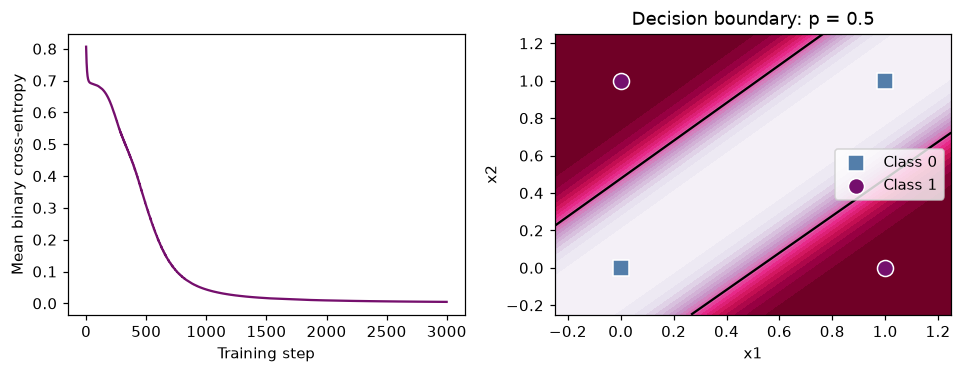

In [12]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(losses, color="#750f6d")
axes[0].set(xlabel="Training step", ylabel="Mean binary cross-entropy")

grid_axis = np.linspace(-0.25, 1.25, 150)
xx, yy = np.meshgrid(grid_axis, grid_axis)
grid = torch.tensor(np.column_stack([xx.ravel(), yy.ravel()]), dtype=torch.float32)
with torch.no_grad():
    grid_probabilities = torch.sigmoid(model(grid)).numpy().reshape(xx.shape)
axes[1].contourf(xx, yy, grid_probabilities, levels=np.linspace(0, 1, 21), cmap="PuRd")
axes[1].contour(xx, yy, grid_probabilities, levels=[0.5], colors="black")
for label, marker, color in [(0, "s", "#537eaa"), (1, "o", "#750f6d")]:
    points = X[y.flatten() == label].numpy()
    axes[1].scatter(points[:, 0], points[:, 1], marker=marker, c=color,
                    s=110, edgecolors="white", label=f"Class {label}")
axes[1].set(xlabel="x1", ylabel="x2", title="Decision boundary: p = 0.5")
axes[1].legend()
fig.tight_layout()
plt.show()

## 8. Compare ReLU with Identity — slides 20–21

`nn.Identity()` returns its input unchanged. Replacing ReLU with Identity
removes the nonlinearity between our two Linear layers.

This is a worked comparison demonstrated by the TA. The code below is already
set to `activation = nn.Identity()`, and the outputs have been saved.
For self-study, first run the cell that defines `run_experiment`, then run the
comparison and plotting cells.

`run_experiment(activation)` is a function defined for this notebook. It builds and
trains a model with the selected hidden activation, then returns the trained model
and its list of training losses.
The function uses the same seed, layer sizes, data, learning rate, and 3000 training steps.
It creates a **new model and a new optimizer** each time, so the optimizer updates the
new model's parameters. We keep the original trained model for comparison.

The original ReLU model has mean training loss about **0.0046**.
Without ReLU, this run gives loss about **0.6931**, with all four probabilities
close to **0.5**. The plot compares the two training-loss curves.
The explanation below connects these results to the formula on slide 21.

In [13]:
def run_experiment(activation):
    # Same seed, architecture sizes, optimizer, and training steps.
    torch.manual_seed(42)
    experiment_model = nn.Sequential(
        nn.Linear(2, 4), activation, nn.Linear(4, 1)
    )
    experiment_optimizer = torch.optim.SGD(
        experiment_model.parameters(), lr=0.1
    )
    experiment_losses = []
    for epoch in range(3000):
        experiment_optimizer.zero_grad()
        experiment_loss = loss_fn(experiment_model(X), y)
        experiment_loss.backward()
        experiment_optimizer.step()
        experiment_losses.append(experiment_loss.item())
    return experiment_model, experiment_losses

In [14]:
activation = nn.Identity()
experiment_model, experiment_losses = run_experiment(activation)
with torch.no_grad():
    experiment_probabilities = torch.sigmoid(experiment_model(X))
    experiment_final_loss = loss_fn(experiment_model(X), y).item()
print(f"Final experiment loss: {experiment_final_loss:.6f}")
print(experiment_probabilities)

Final experiment loss: 0.693147
tensor([[0.5000],
        [0.5000],
        [0.5000],
        [0.5000]])


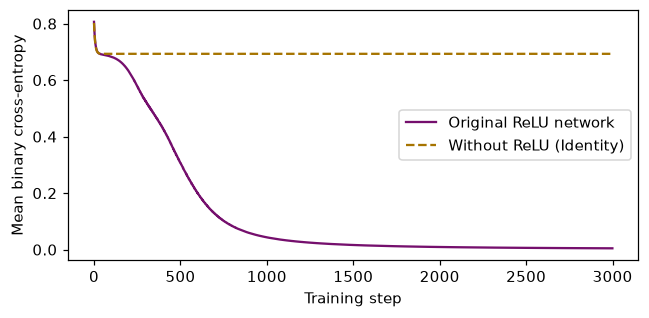

In [15]:
plt.figure(figsize=(6, 3))
plt.plot(losses, label="Original ReLU network", color="#750f6d")
plt.plot(experiment_losses, label="Without ReLU (Identity)", color="#a67400", linestyle="--")
plt.xlabel("Training step")
plt.ylabel("Mean binary cross-entropy")
plt.legend()
plt.tight_layout()
plt.show()

## What the comparison shows

Without ReLU, the two Linear layers reduce to one weighted sum plus a bias:

$$z=W_2(W_1x+b_1)+b_2=(W_2W_1)x+(W_2b_1+b_2).$$

At a probability threshold of 0.5, the decision boundary is where $z=0$.
This is a straight line in the two input coordinates, so it cannot separate
all four XOR samples correctly. ReLU lets our original network use a more
flexible boundary.

The loss of about 0.6931 and probabilities close to 0.5 are the results of
this particular run. Both models were evaluated on their training samples;
these results do not measure performance on new data.

**Rerunning the comparison:** run the `run_experiment` function-definition cell,
followed by the comparison and plotting cells. The function starts a fresh
model and optimizer each time.

**If you need to rerun the main demonstration:** rerun the model cell, the loss/optimizer
cell, and then the training and prediction cells. Running only the training cell
continues updating the existing model; it does not start a fresh experiment.

## References

- Course Lecture 7: Neural Network Basics.
- [PyTorch autograd](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html)
- [PyTorch optimization](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)
- [BCEWithLogitsLoss](https://docs.pytorch.org/docs/main/generated/torch.nn.BCEWithLogitsLoss.html)